
# Lab 2: Country Schools Data Analysis

## 1. Introduction

This lab focuses on basic data preprocessing and the application of two Computing Intelligence techniques: anomaly detection and cluster analysis. The Country Schools dataset will be used to identify unusual records and group schools with similar characteristics.


In [1]:
import pandas as pd
#Loading country schools dataset
schoolsData=pd.read_csv("/kaggle/input/datasets/mukaberayvonne/lab2-dataset/Country Schools.csv")
print("Dataset loaded successfully:", schoolsData.shape)

Dataset loaded successfully: (50, 8)


In [2]:
#First five records
schoolsData.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [3]:
#last five records
schoolsData.tail()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50



## 2. Data Inspection

In this section, i will inspect the Country Schools dataset to understand its structure, identify the data types of its columns, and determine the number of records and features available for analysis.


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,InstalledLDDs,InstalledTDDs,FID
count,48.00,48.00,48.00,48.00,48.00,50.00
mean,905.38,609.54,295.83,30150.75,1219.08,25.50
std,3079.87,2078.97,1009.29,102851.95,4157.94,14.58
min,93.00,8.00,4.00,606.00,16.00,1.00
25%,271.75,161.25,53.25,6289.00,322.50,13.25
50%,422.50,314.50,130.50,14165.00,629.00,25.50
75%,637.00,420.25,247.75,23215.00,840.50,37.75
max,21729.00,14629.00,7100.00,723618.00,29258.00,50.00


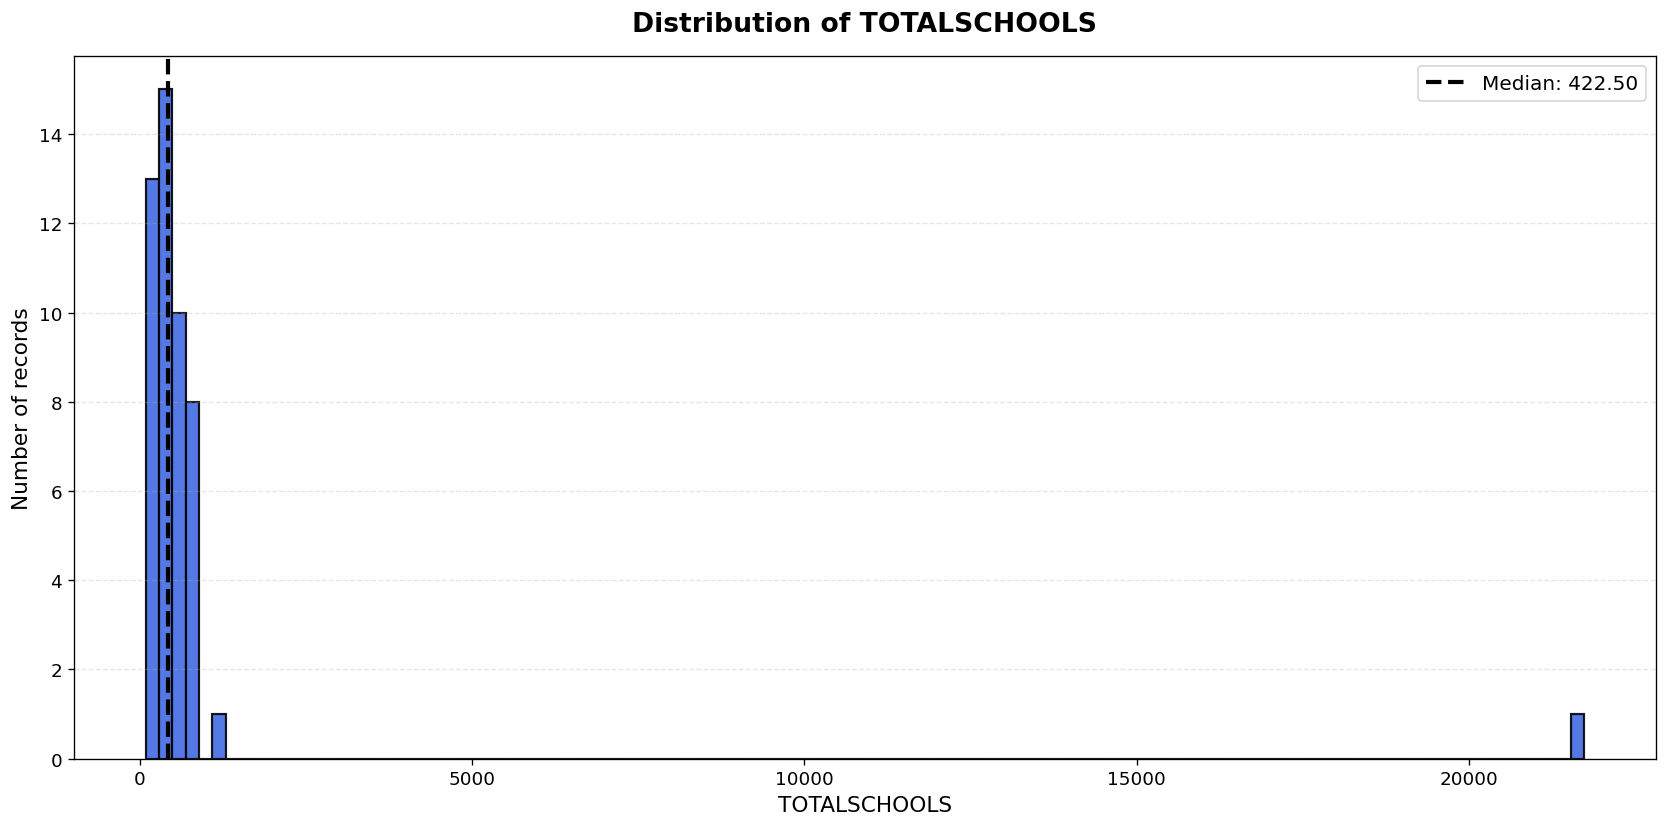

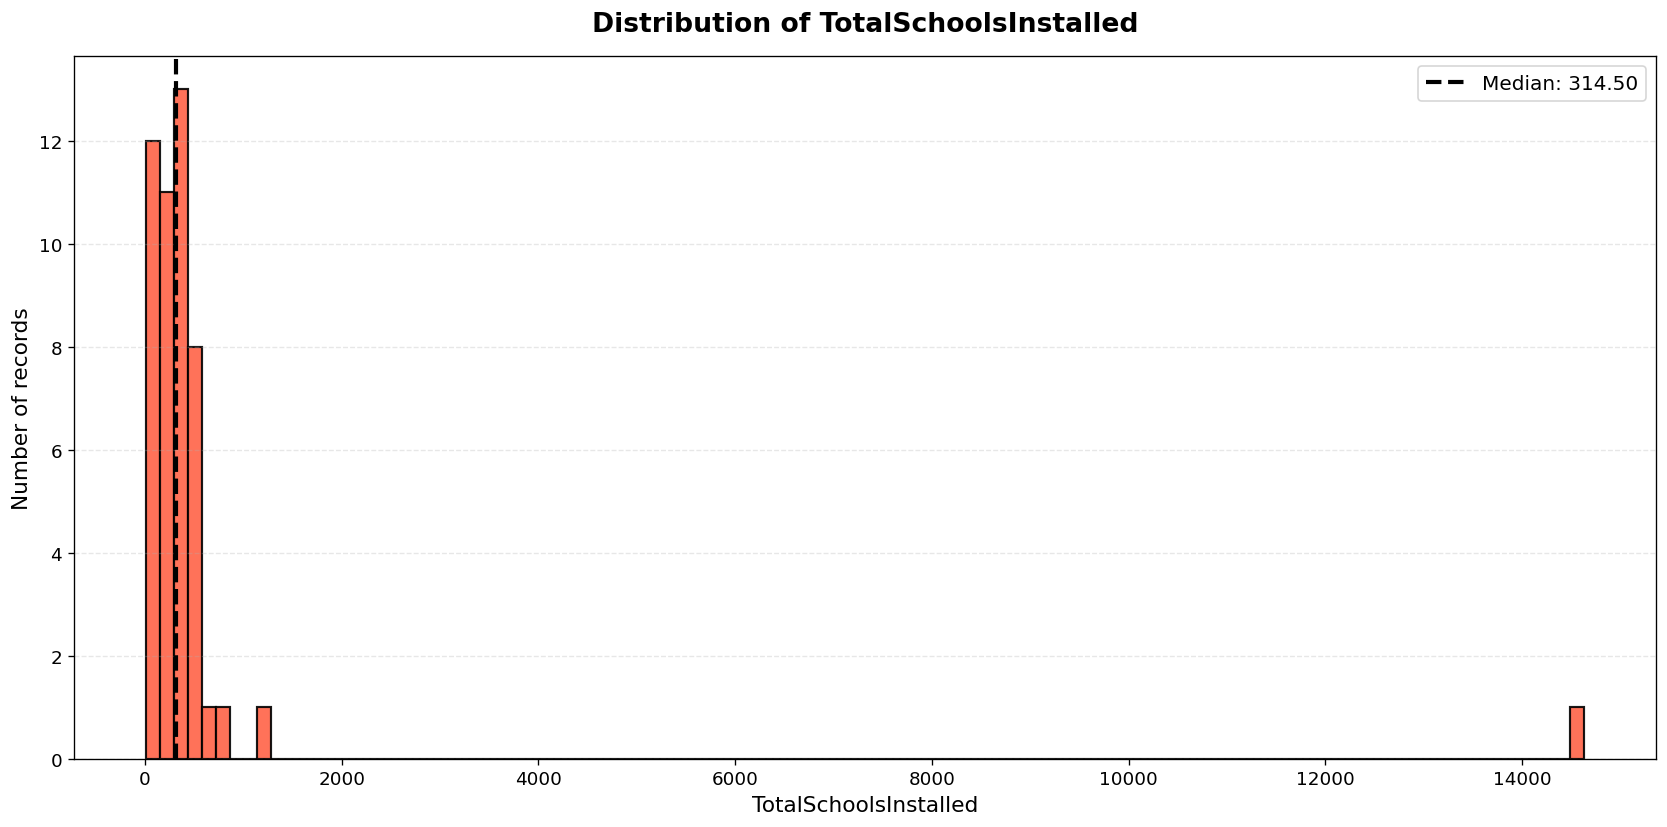

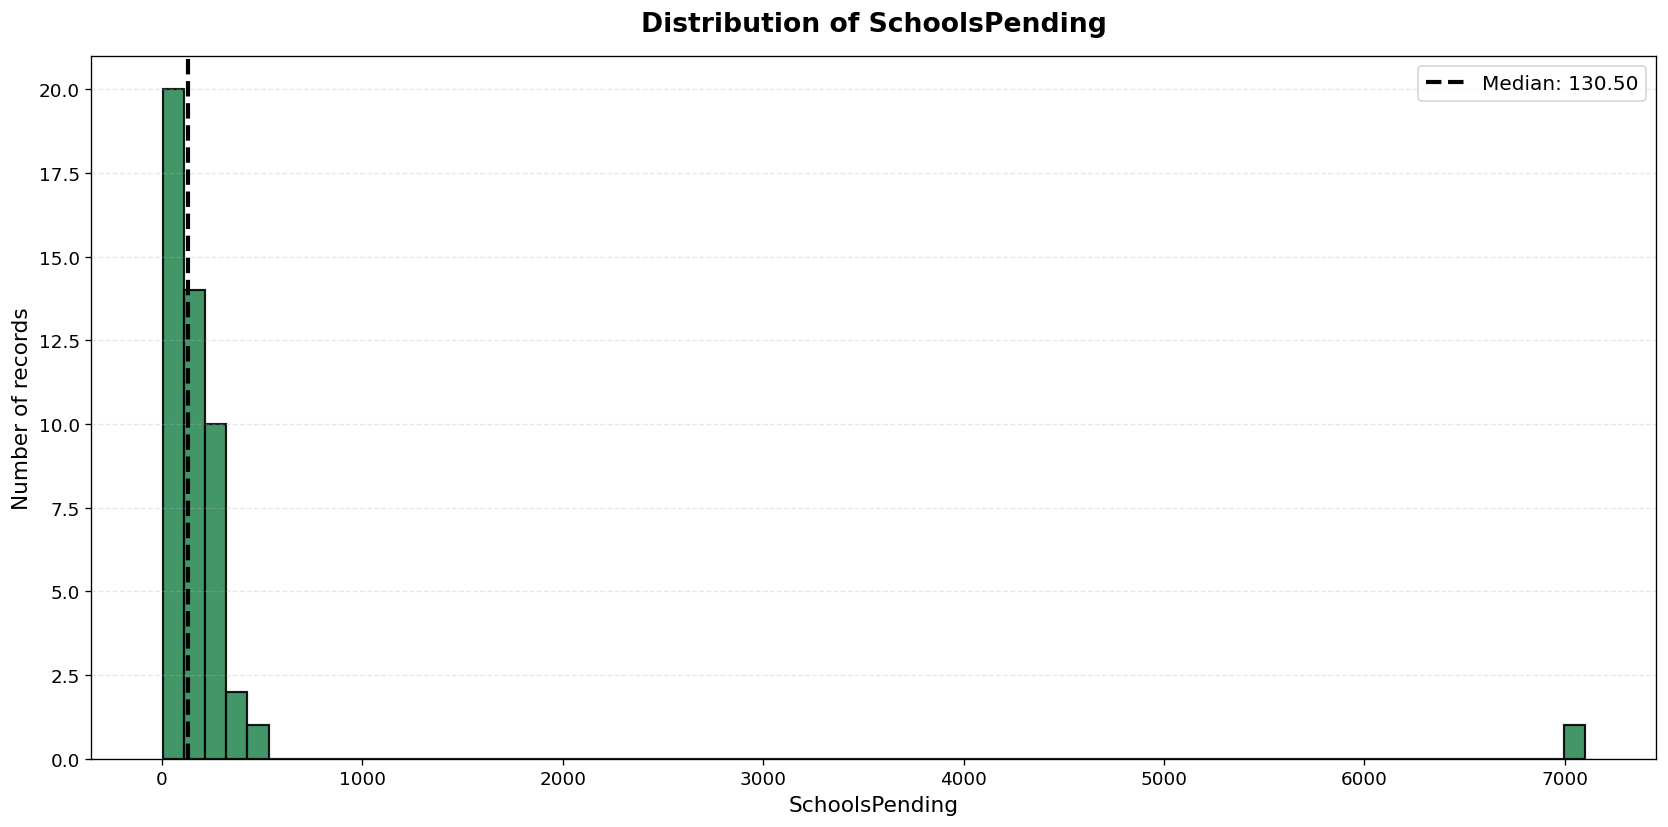

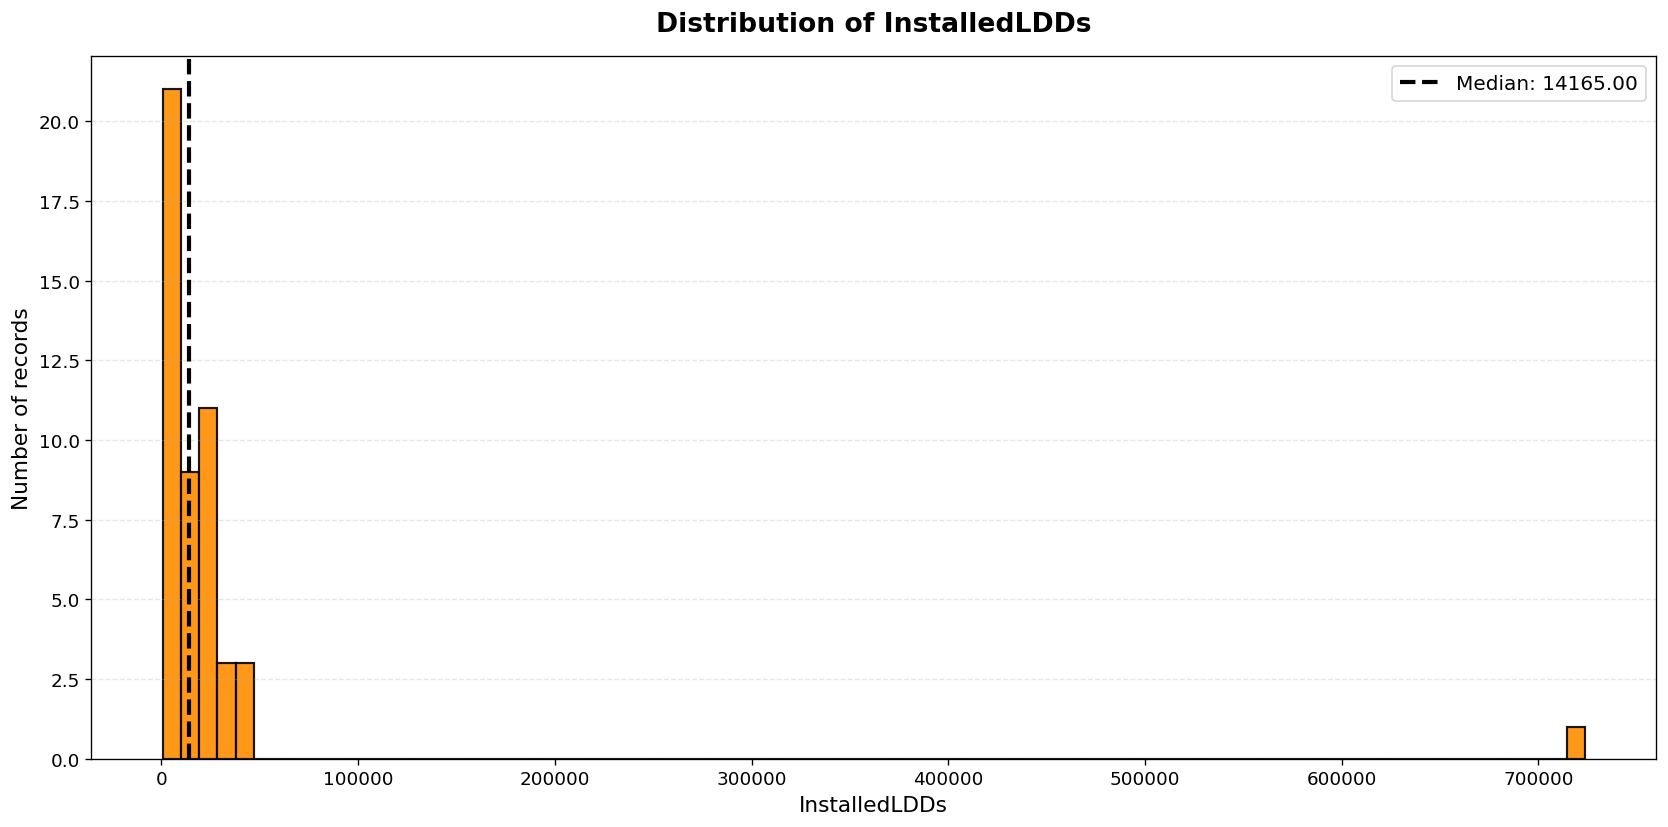

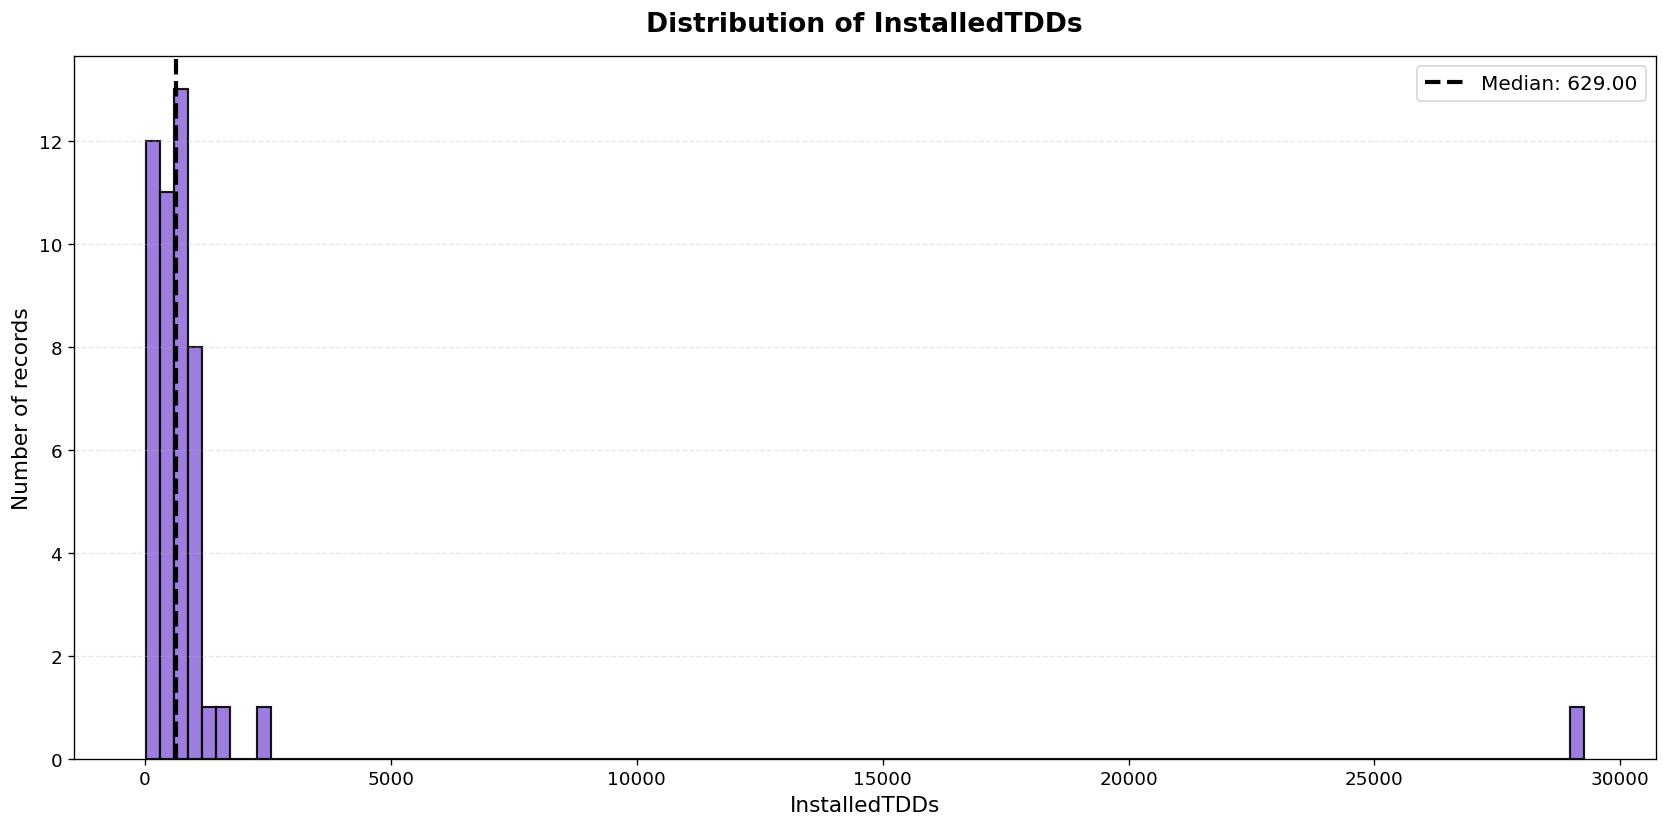

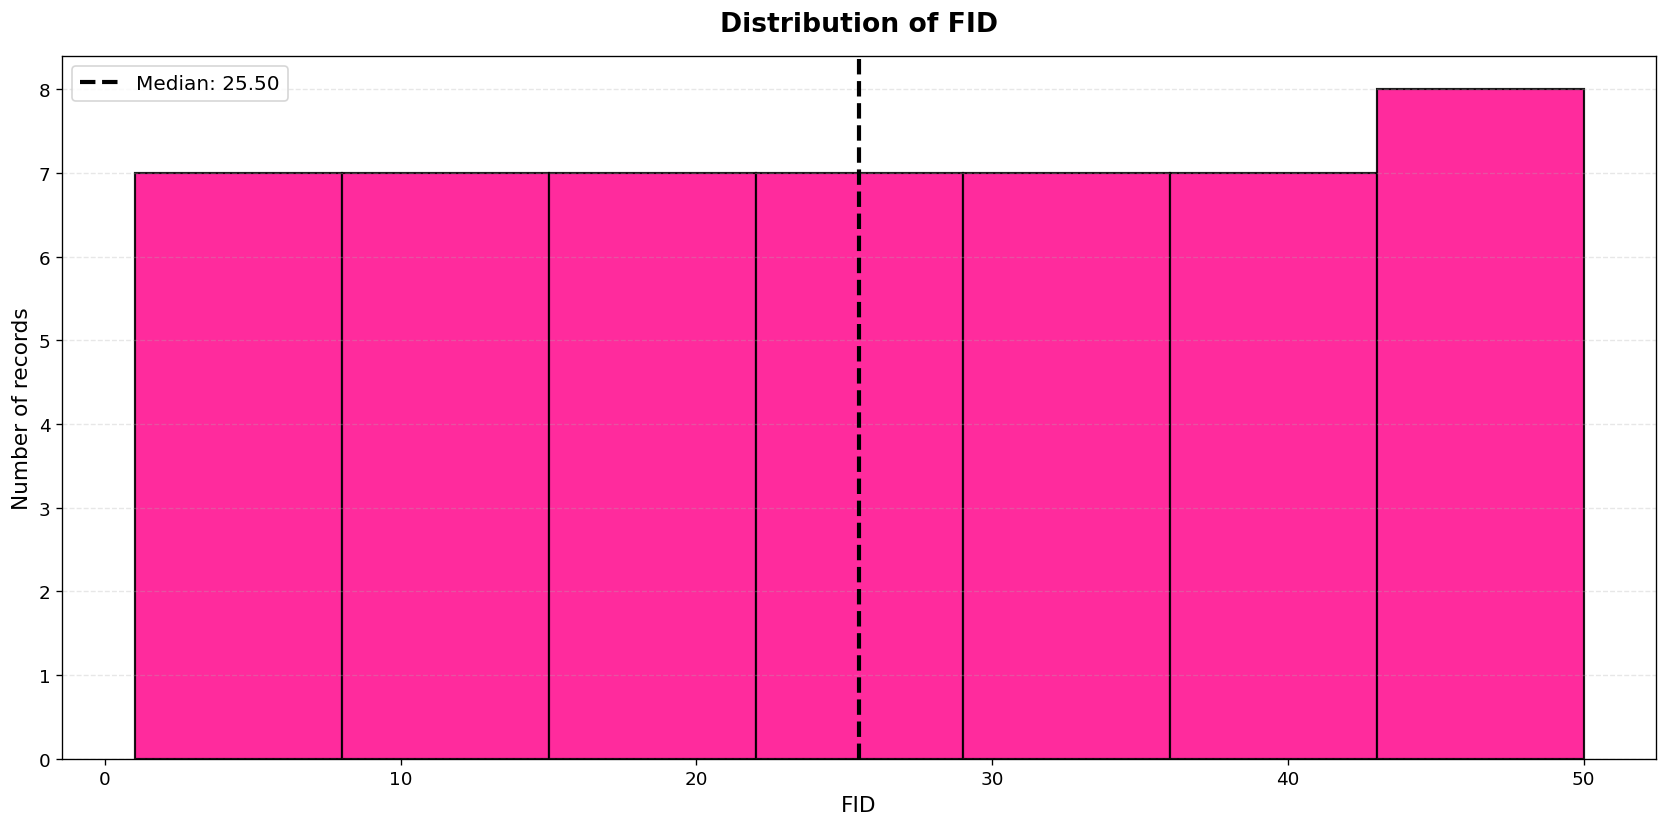

In [4]:
import matplotlib.pyplot as plt

numericalData = schoolsData.select_dtypes(include="number")

#Numerical summary
display(numericalData.describe().round(2))

colors = [
    "royalblue", "tomato", "seagreen", "darkorange",
    "mediumpurple", "deeppink", "teal", "gold",
    "slateblue", "coral"
]

# Displaying on histogram 
for i, column in enumerate(numericalData.columns):
    values = numericalData[column].dropna()

    fig, ax = plt.subplots(figsize=(14, 7), dpi=120)

    ax.hist(
        values,
        bins="auto",
        color=colors[i % len(colors)],
        edgecolor="black",
        linewidth=1.3,
        alpha=0.9
    )

    ax.axvline(
        values.median(),
        color="black",
        linestyle="--",
        linewidth=2.5,
        label=f"Median: {values.median():.2f}"
    )

    ax.set_title(
        f"Distribution of {column}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel(column, fontsize=13)
    ax.set_ylabel("Number of records", fontsize=13)
    ax.tick_params(axis="both", labelsize=11)
    ax.legend(fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


## 3. Data Preprocessing

### 3.1 Checking Missing Values and Duplicate Records

In this step, i will check the dataset for missing values and duplicate records. This helps us identify data quality issues before applying anomaly detection and cluster analysis.


In [5]:
# Count missing values in each column
print("Missing values per column:")
display(schoolsData.isna().sum().to_frame(name="Missing Values"))

# Calculate the total number of missing values
print("Total missing values:", schoolsData.isna().sum().sum())

# Count duplicate records
print("\nNumber of duplicate rows:", schoolsData.duplicated().sum())

Missing values per column:


,Missing Values
SNO,2
TOTALSCHOOLS,2
TotalSchoolsInstalled,2
SchoolsPending,2
PercentageInstalled,2
InstalledLDDs,2
InstalledTDDs,2
FID,0


Total missing values: 14

Number of duplicate rows: 0



### 3.2 Handling Missing Values(Data Cleaning)

The dataset contains 14 missing values across seven columns, with two missing values in each column. No duplicate records were found. In this step, I will remove records that contain missing values to prepare a complete dataset for further analysis.


In [6]:

# Remove rows containing missing values
schoolsData = schoolsData.dropna().copy()

# Verify the cleaned dataset
print("\nMissing values after cleaning:")
display(schoolsData.isnull().sum())

print("Dataset shape after cleaning:", schoolsData.shape)

display(schoolsData.head())



Missing values after cleaning:


SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Dataset shape after cleaning: (48, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


#### Checking Feature Data Types

Before scaling the selected features, we will inspect their data types and sample values to identify any columns containing non-numeric data.

In [7]:

# Select the numerical features
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Check the data types of the selected features
print("Feature data types:")
display(schoolsData[featureColumns].dtypes.to_frame(name="Data Type"))

# Display sample values
print("Sample values:")
display(schoolsData[featureColumns].head())

# Check for non-numeric values
print("Non-numeric values:")
for column in featureColumns:
    nonNumeric = pd.to_numeric(schoolsData[column], errors="coerce").isna().sum()
    print(f"{column}: {nonNumeric}")


Feature data types:


,Data Type
TOTALSCHOOLS,float64
TotalSchoolsInstalled,float64
SchoolsPending,float64
PercentageInstalled,object
InstalledLDDs,float64
InstalledTDDs,float64


Sample values:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,37.0,321.0,10.34%,3744.0,74.0
1,875.0,552.0,323.0,63.09%,22982.0,1104.0
2,498.0,242.0,256.0,48.59%,15114.0,484.0
3,1238.0,1200.0,38.0,96.93%,42162.0,2400.0
4,159.0,143.0,16.0,89.94%,7415.0,286.0


Non-numeric values:
TOTALSCHOOLS: 0
TotalSchoolsInstalled: 0
SchoolsPending: 0
PercentageInstalled: 48
InstalledLDDs: 0
InstalledTDDs: 0


#### Converting Percentage Values

The `PercentageInstalled` column contains percentage signs, causing it to be stored as text. We will remove the signs and convert the column to a numerical data type so it can be used in anomaly detection and cluster analysis.

In [8]:

from sklearn.preprocessing import StandardScaler

# Remove percentage signs and convert values to numbers
schoolsData["PercentageInstalled"] = pd.to_numeric(
    schoolsData["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="raise"
)

# Select the features for analysis
schoolsFeatures = schoolsData[featureColumns].copy()

# Standardize the selected features
scaler = StandardScaler()
schoolsScaled = scaler.fit_transform(schoolsFeatures)

# Display data types and shapes
print("Data types:")
print(schoolsFeatures.dtypes)

print("\nOriginal feature shape:", schoolsFeatures.shape)
print("Scaled feature shape:", schoolsScaled.shape)

# Display the scaled feature values
display(
    pd.DataFrame(schoolsScaled, columns=featureColumns)
    .head()
    .round(2)
)


Data types:
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled      float64
InstalledLDDs            float64
InstalledTDDs            float64
dtype: object

Original feature shape: (48, 6)
Scaled feature shape: (48, 6)


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,-0.18,-0.28,0.03,-2.12,-0.26,-0.28
1,-0.01,-0.03,0.03,-0.04,-0.07,-0.03
2,-0.13,-0.18,-0.04,-0.61,-0.15,-0.18
3,0.11,0.29,-0.26,1.30,0.12,0.29
4,-0.24,-0.23,-0.28,1.03,-0.22,-0.23


## 4. Anomaly Detection

Anomaly detection identifies records that differ substantially from the general pattern in the dataset. In this experiment, we use the Isolation Forest algorithm to identify potentially unusual school statistics based on the six selected numerical features.

In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Select numerical features
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Prepare county data and exclude the aggregate TOTAL row
anomalyResults = schoolsData[
    schoolsData["SNO"].astype(str).str.strip().str.upper() != "TOTAL"
].copy()

# Convert percentage values to numerical values
anomalyResults["PercentageInstalled"] = pd.to_numeric(
    anomalyResults["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

# Ensure all selected features are numerical
for column in featureColumns:
    anomalyResults[column] = pd.to_numeric(
        anomalyResults[column],
        errors="coerce"
    )

# Remove records with missing feature values
anomalyResults = anomalyResults.dropna(
    subset=featureColumns
).copy()

# Standardize the features
scaler = StandardScaler()
schoolsScaled = scaler.fit_transform(
    anomalyResults[featureColumns]
)

# Create and train the anomaly detection model
anomalyModel = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Identify normal records and potential anomalies
anomalyLabels = anomalyModel.fit_predict(schoolsScaled)

# Add results to the same dataset used for detection
anomalyResults["AnomalyStatus"] = anomalyLabels

# Summarize the results
print("Anomaly Detection Results:")
print("Total counties:", len(anomalyResults))
print("Normal counties:", (anomalyLabels == 1).sum())
print("Potential anomalies:", (anomalyLabels == -1).sum())

# Display potential anomalies
print("\nPotential Anomalous Counties:")
display(
    anomalyResults[
        anomalyResults["AnomalyStatus"] == -1
    ]
)

Anomaly Detection Results:
Total counties: 47
Normal counties: 34
Potential anomalies: 13

Potential Anomalous Counties:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID,AnomalyStatus
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1,-1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2,-1
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4,-1
11,NANDI,709.0,673.0,36.0,94.92,27780.0,1346.0,12,-1
13,MAKUENI,887.0,833.0,54.0,93.91,30973.0,1666.0,14,-1
14,LAMU,93.0,89.0,4.0,95.70,3083.0,178.0,15,-1
17,KAKAMEGA,880.0,572.0,308.0,65.00,44338.0,1144.0,18,-1
18,BUNGOMA,741.0,456.0,285.0,61.54,38744.0,912.0,19,-1
28,GARISSA,163.0,31.0,132.0,19.02,1569.0,62.0,29,-1
30,MANDERA,198.0,9.0,189.0,4.55,1046.0,18.0,31,-1


### 4.1 Interpretation of Results

The Isolation Forest model classified 41 records as normal and flagged 7 as potential anomalies. This represents approximately 14.6% of the dataset. The flagged records include counties with low installation rates, counties with high installation rates, and a row representing the overall total. These records have unusual combinations of features compared with the rest of the dataset and may require further investigation. The results do not necessarily indicate incorrect data.

Overall Anomaly Detection Results
Total counties: 47
Normal counties: 34
Potential anomalies: 13

Potential Anomalous Counties:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0
11,NANDI,709.0,673.0,36.0,94.92,27780.0,1346.0
13,MAKUENI,887.0,833.0,54.0,93.91,30973.0,1666.0
14,LAMU,93.0,89.0,4.0,95.70,3083.0,178.0
17,KAKAMEGA,880.0,572.0,308.0,65.00,44338.0,1144.0
18,BUNGOMA,741.0,456.0,285.0,61.54,38744.0,912.0
28,GARISSA,163.0,31.0,132.0,19.02,1569.0,62.0
30,MANDERA,198.0,9.0,189.0,4.55,1046.0,18.0


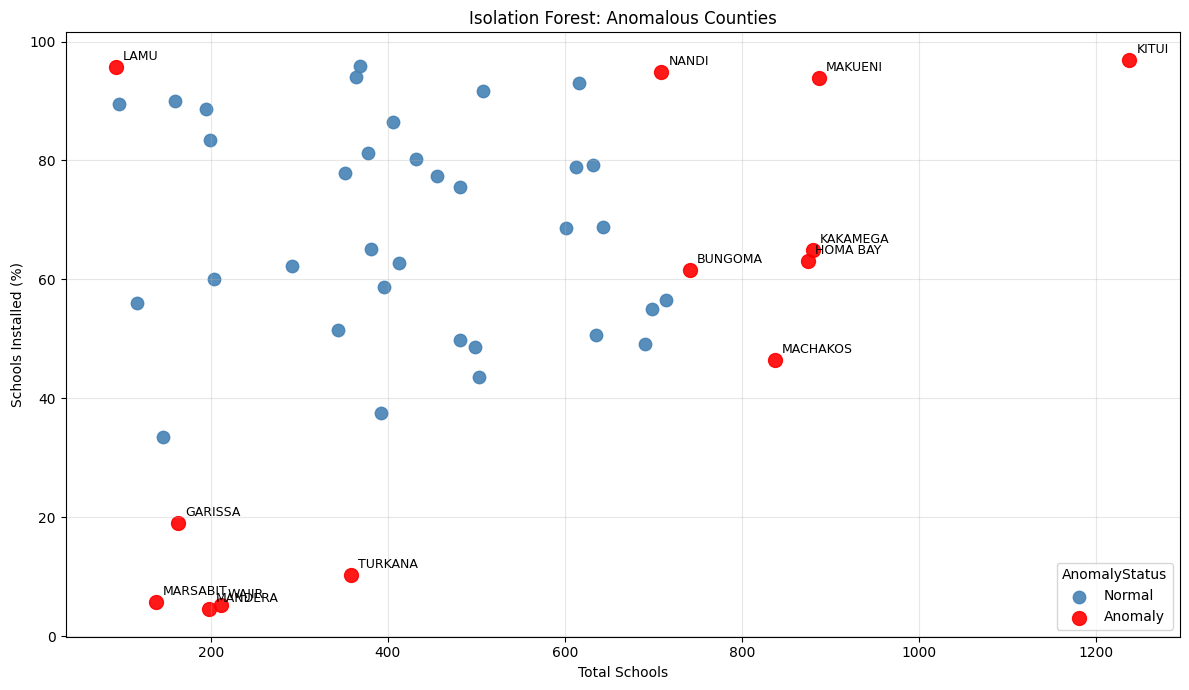

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Select numerical features
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Exclude the aggregate TOTAL row
countyMask = (
    schoolsData["SNO"].astype(str).str.strip().str.upper() != "TOTAL"
)

countyData = schoolsData.loc[countyMask].copy()

# Convert percentage values to numerical values
countyData["PercentageInstalled"] = pd.to_numeric(
    countyData["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

# Ensure all selected features are numerical
for column in featureColumns:
    countyData[column] = pd.to_numeric(
        countyData[column],
        errors="coerce"
    )

# Remove records with missing feature values
countyData = countyData.dropna(subset=featureColumns).copy()

# Standardize the numerical features
scaler = StandardScaler()
schoolsScaled = scaler.fit_transform(countyData[featureColumns])

# Detect potential anomalies
isolationForest = IsolationForest(
    contamination="auto",
    random_state=42
)

countyData["Anomaly"] = isolationForest.fit_predict(schoolsScaled)

# Display overall anomaly detection results
totalRecords = len(countyData)
normalCount = (countyData["Anomaly"] == 1).sum()
anomalyCount = (countyData["Anomaly"] == -1).sum()

print("Overall Anomaly Detection Results")
print(f"Total counties: {totalRecords}")
print(f"Normal counties: {normalCount}")
print(f"Potential anomalies: {anomalyCount}")

# Display potential anomalous counties
print("\nPotential Anomalous Counties:")
display(
    countyData.loc[
        countyData["Anomaly"] == -1,
        ["SNO"] + featureColumns
    ]
)

# Visualize anomaly detection results
normalData = countyData[countyData["Anomaly"] == 1]
anomalyData = countyData[countyData["Anomaly"] == -1]

plt.figure(figsize=(12, 7))

# Plot normal counties
plt.scatter(
    normalData["TOTALSCHOOLS"],
    normalData["PercentageInstalled"],
    color="steelblue",
    label="Normal",
    s=80,
    alpha=0.9
)

# Plot potential anomalies
plt.scatter(
    anomalyData["TOTALSCHOOLS"],
    anomalyData["PercentageInstalled"],
    color="red",
    label="Anomaly",
    s=100,
    alpha=0.9
)

# Label anomalous counties
for _, row in anomalyData.iterrows():
    plt.annotate(
        str(row["SNO"]),
        (row["TOTALSCHOOLS"], row["PercentageInstalled"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Isolation Forest: Anomalous Counties")
plt.xlabel("Total Schools")
plt.ylabel("Schools Installed (%)")
plt.legend(title="AnomalyStatus")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Cluster Analysis

Cluster analysis groups records with similar characteristics. In this experiment, we use the K-Means algorithm to group school records based on total schools, installation progress, pending schools, and installed LDDs and TDDs. The six features are standardized so differences in their numerical ranges do not dominate the clustering process.

### 5.1 Interpretation of Cluster Groups

K-Means divided the 47 individual counties into four clusters. Cluster 0 contains 9 counties, Cluster 1 contains 19 counties, Cluster 2 contains 15 counties, and Cluster 3 contains 4 counties.

The cluster labels do not represent rankings. Each group contains counties with similar school installation characteristics. To understand the differences between the groups, we compare their average values across the selected school features.

### 5.2 Visualizing the Four Clusters

A scatter plot and bar chart are used to visualize the county groups and compare their average school installation percentages.

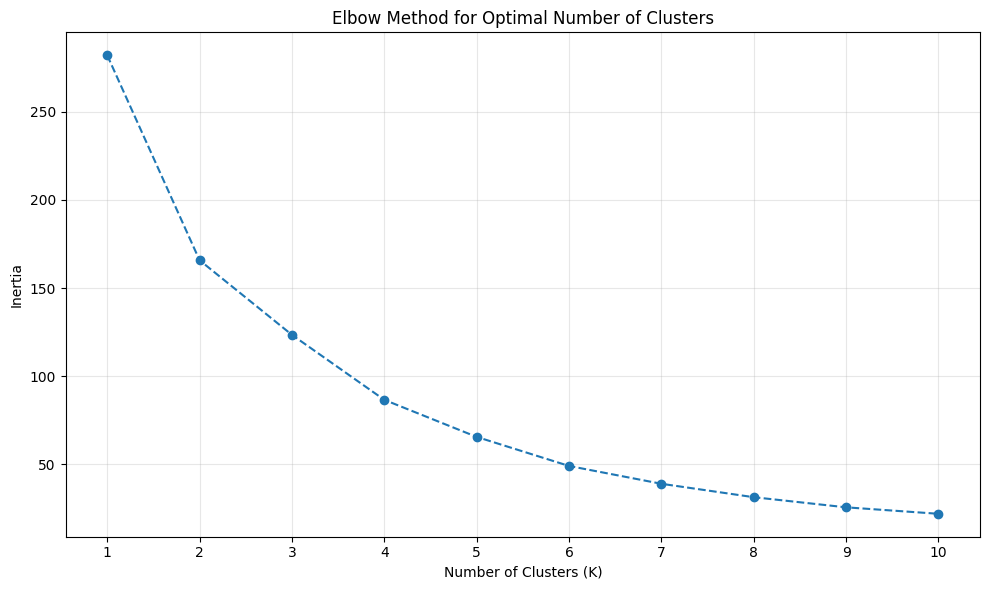

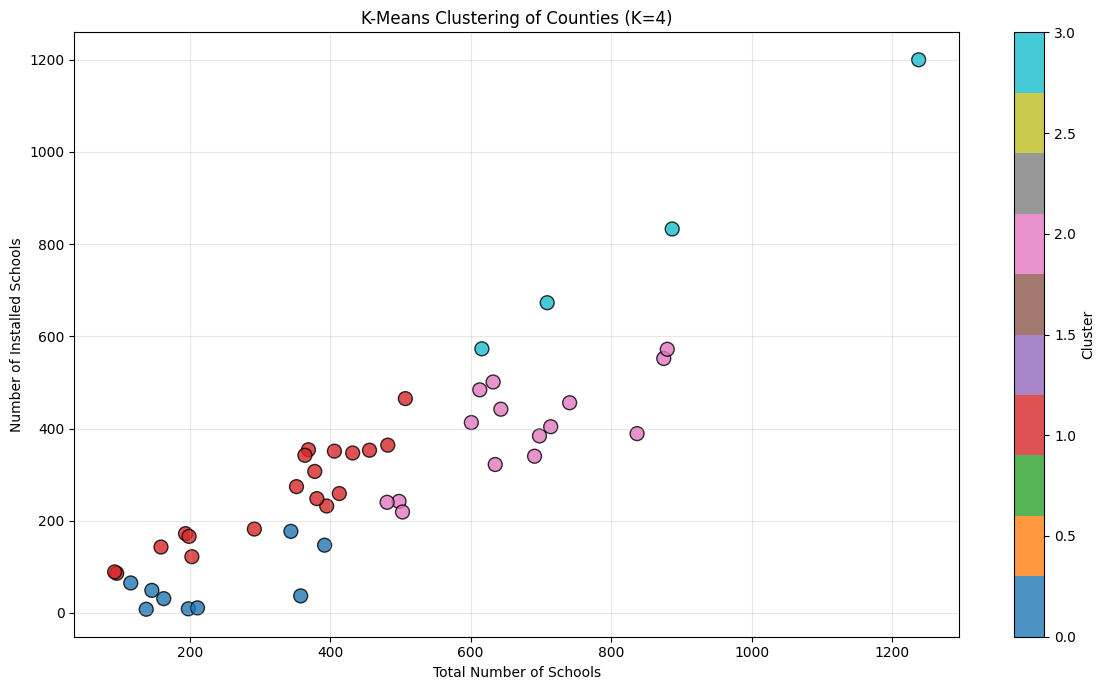

Number of counties in each cluster:


,Number of Counties
Cluster,
0,9
1,19
2,15
3,4


Average characteristics of each cluster:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,,,
0,229.56,59.33,170.22,24.83,2581.44,118.67
1,324.79,255.58,69.21,79.82,13015.63,511.16
2,669.47,397.33,272.13,59.02,21290.93,794.67
3,862.50,819.75,42.75,94.70,33431.00,1639.50


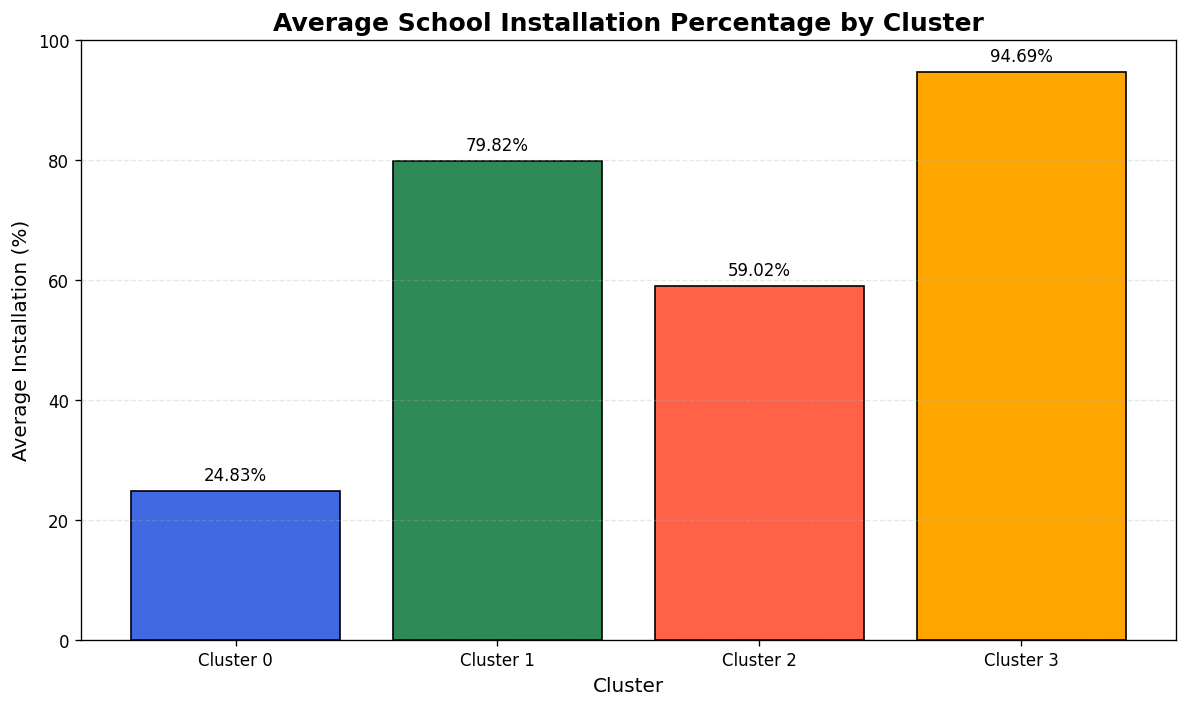

In [11]:

# CLUSTERING ANALYSIS USING K-MEANS

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare the county data
# Exclude the aggregate TOTAL row
countyMask = schoolsData["SNO"].astype(str).str.strip().str.upper() != "TOTAL"
countyData = schoolsData.loc[countyMask].copy()

# Select numerical features for clustering
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Convert percentage values to numerical values if necessary
countyData["PercentageInstalled"] = pd.to_numeric(
    countyData["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

# Ensure all selected features are numerical
for column in featureColumns:
    countyData[column] = pd.to_numeric(
        countyData[column],
        errors="coerce"
    )

# Remove rows with missing feature values
countyData = countyData.dropna(subset=featureColumns).copy()

# Standardize the selected features
X = countyData[featureColumns]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# ELBOW METHOD

inertiaValues = []
kValues = range(1, 11)

for k in kValues:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertiaValues.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(10, 6))

plt.plot(
    kValues,
    inertiaValues,
    marker="o",
    linestyle="--"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(kValues))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# APPLY K-MEANS CLUSTERING

# Select four clusters based on the Elbow Method
optimalK = 4

kmeans = KMeans(
    n_clusters=optimalK,
    random_state=42,
    n_init=10
)

countyData["Cluster"] = kmeans.fit_predict(X_scaled)


# K-MEANS SCATTER PLOT

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    countyData["TOTALSCHOOLS"],
    countyData["TotalSchoolsInstalled"],
    c=countyData["Cluster"],
    cmap="tab10",
    s=100,
    alpha=0.8,
    edgecolors="black"
)

plt.title("K-Means Clustering of Counties (K=4)")
plt.xlabel("Total Number of Schools")
plt.ylabel("Number of Installed Schools")

plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# DISPLAY NUMBER OF COUNTIES IN EACH CLUSTER

clusterCounts = countyData["Cluster"].value_counts().sort_index()

print("Number of counties in each cluster:")
display(clusterCounts.to_frame(name="Number of Counties"))


# DISPLAY CLUSTER PROFILES

clusterProfiles = countyData.groupby("Cluster")[featureColumns].mean()

print("Average characteristics of each cluster:")
display(clusterProfiles.round(2))


# DISPLAY AVERAGE INSTALLATION PERCENTAGE BY CLUSTER

clusterPercentages = clusterProfiles["PercentageInstalled"]

plt.figure(figsize=(10, 6), dpi=120)

bars = plt.bar(
    [f"Cluster {cluster}" for cluster in clusterPercentages.index],
    clusterPercentages.values,
    color=["royalblue", "seagreen", "tomato", "orange"],
    edgecolor="black"
)

plt.title(
    "Average School Installation Percentage by Cluster",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Cluster", fontsize=12)
plt.ylabel("Average Installation (%)", fontsize=12)
plt.ylim(0, 100)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### 5.3. Interpretation of Results

Isolation Forest identified seven potential anomalies, including six counties and the aggregate `TOTAL` record. K-Means grouped the 47 counties into four clusters, showing different levels of school installation progress. Cluster 0 had the lowest average installation rate (24.83%), while Cluster 3 had the highest (94.70%).

## 6. Limitations

- The dataset contains only 47 counties after cleaning.
- Detected anomalies may represent unusual patterns, not necessarily errors.
- The Elbow Method guides the choice of clusters but does not guarantee the best grouping.
- The analysis uses only available school installation data and excludes other factors that may affect progress.